## Veriye İlk Bakış

In [13]:
import seaborn as sns
import pandas as pd
planets = sns.load_dataset("planets")
df = planets.copy()
df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


In [14]:
#Bu veri seti nasıl, neden ve kim tarafından oluşturuldu, incele. Data seti ilk başta hakkında konuşabilecek kadar analiz et

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1035 entries, 0 to 1034
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   method          1035 non-null   str    
 1   number          1035 non-null   int64  
 2   orbital_period  992 non-null    float64
 3   mass            513 non-null    float64
 4   distance        808 non-null    float64
 5   year            1035 non-null   int64  
dtypes: float64(3), int64(2), str(1)
memory usage: 48.6 KB


In [17]:
df.method = pd.Categorical(df.method)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1035 entries, 0 to 1034
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   method          1035 non-null   category
 1   number          1035 non-null   int64   
 2   orbital_period  992 non-null    float64 
 3   mass            513 non-null    float64 
 4   distance        808 non-null    float64 
 5   year            1035 non-null   int64   
dtypes: category(1), float64(3), int64(2)
memory usage: 41.6 KB


In [19]:
df.dtypes

method            category
number               int64
orbital_period     float64
mass               float64
distance           float64
year                 int64
dtype: object

In [20]:
df.shape

(1035, 6)

In [21]:
df.columns

Index(['method', 'number', 'orbital_period', 'mass', 'distance', 'year'], dtype='str')

In [25]:
df.describe().T #Sayısal değişkenleri gösterir, anlamlar çıkarmaya çalışırız başta

,count,mean,std,min,25%,50%,75%,max
number,1035.0,1.785507,1.240976,1.000000,1.00000,1.0000,2.000,7.0
orbital_period,992.0,2002.917596,26014.728304,0.090706,5.44254,39.9795,526.005,730000.0
mass,513.0,2.638161,3.818617,0.003600,0.22900,1.2600,3.040,25.0
distance,808.0,264.069282,733.116493,1.350000,32.56000,55.2500,178.500,8500.0
year,1035.0,2009.070531,3.972567,1989.000000,2007.00000,2010.0000,2012.000,2014.0


## Eksik Değerlerin İncelenmesi

In [2]:
import seaborn as sns
import pandas as pd
planets = sns.load_dataset("planets")
df = planets.copy()
df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


In [6]:
#hiç eksik değer var mı
df.isnull().values.any()

np.True_

In [39]:
#hangi sütunda kaç eksik değer var
df.isnull().sum()

method              0
number              0
orbital_period     43
mass              522
distance          227
year                0
dtype: int64

In [40]:
df["mass"] = df["mass"].fillna(df.mass.mean())
df.isnull().sum()

method              0
number              0
orbital_period     43
mass                0
distance          227
year                0
dtype: int64

## Kategorik Değişkenleri İnceleme

In [41]:
import seaborn as sns
import pandas as pd
planets = sns.load_dataset("planets")
df = planets.copy()
df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


In [42]:
df.dtypes

method                str
number              int64
orbital_period    float64
mass              float64
distance          float64
year                int64
dtype: object

In [46]:
df_cat = df.select_dtypes(include= ["str"])
df_cat.head()

,method
0,Radial Velocity
1,Radial Velocity
2,Radial Velocity
3,Radial Velocity
4,Radial Velocity


In [57]:
print(df_cat.method.unique(),"\n") #birbirinden farklı kategorik değişkenleri 
print(df_cat["method"].value_counts(),"\n") #kategorik değişkenlerin frekans bilgisi
print(df_cat["method"].value_counts().count(),"\n") #birbirinden farklı kategorik değişkenlerin sayıları 

<StringArray>
[              'Radial Velocity',                       'Imaging',
     'Eclipse Timing Variations',                       'Transit',
                    'Astrometry',     'Transit Timing Variations',
 'Orbital Brightness Modulation',                  'Microlensing',
                 'Pulsar Timing',   'Pulsation Timing Variations']
Length: 10, dtype: str 

method
Radial Velocity                  553
Transit                          397
Imaging                           38
Microlensing                      23
Eclipse Timing Variations          9
Pulsar Timing                      5
Transit Timing Variations          4
Orbital Brightness Modulation      3
Astrometry                         2
Pulsation Timing Variations        1
Name: count, dtype: int64 

10 



<Axes: ylabel='method'>

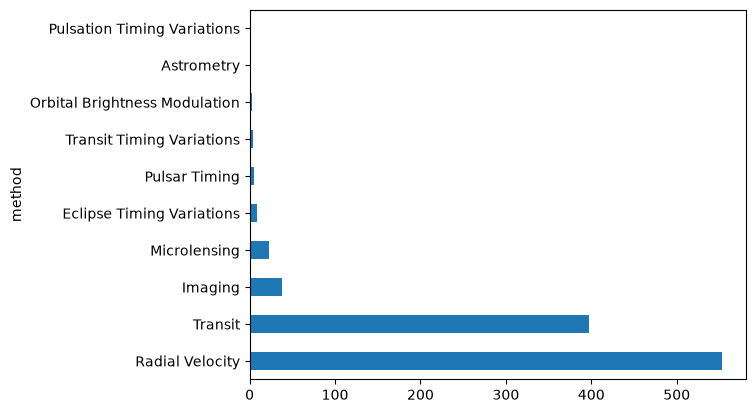

In [59]:
df_cat["method"].value_counts().plot.barh()

## Sürekli Değişkenleri İnceleme

In [60]:
import seaborn as sns
import pandas as pd
planets = sns.load_dataset("planets")
df = planets.copy()
df.head()

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300,7.10,77.40,2006
1,Radial Velocity,1,874.774,2.21,56.95,2008
2,Radial Velocity,1,763.000,2.60,19.84,2011
3,Radial Velocity,1,326.030,19.40,110.62,2007
4,Radial Velocity,1,516.220,10.50,119.47,2009


In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1035 entries, 0 to 1034
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   method          1035 non-null   str    
 1   number          1035 non-null   int64  
 2   orbital_period  992 non-null    float64
 3   mass            513 non-null    float64
 4   distance        808 non-null    float64
 5   year            1035 non-null   int64  
dtypes: float64(3), int64(2), str(1)
memory usage: 48.6 KB


In [64]:
df_num = df.select_dtypes(include=["int64","float64"])
df_num

,number,orbital_period,mass,distance,year
0,1,269.300000,7.10,77.40,2006
1,1,874.774000,2.21,56.95,2008
2,1,763.000000,2.60,19.84,2011
3,1,326.030000,19.40,110.62,2007
4,1,516.220000,10.50,119.47,2009
...,...,...,...,...,...
1030,1,3.941507,NaN,172.00,2006
1031,1,2.615864,NaN,148.00,2007
1032,1,3.191524,NaN,174.00,2007
1033,1,4.125083,NaN,293.00,2008


In [65]:
df_num.describe().T

,count,mean,std,min,25%,50%,75%,max
number,1035.0,1.785507,1.240976,1.000000,1.00000,1.0000,2.000,7.0
orbital_period,992.0,2002.917596,26014.728304,0.090706,5.44254,39.9795,526.005,730000.0
mass,513.0,2.638161,3.818617,0.003600,0.22900,1.2600,3.040,25.0
distance,808.0,264.069282,733.116493,1.350000,32.56000,55.2500,178.500,8500.0
year,1035.0,2009.070531,3.972567,1989.000000,2007.00000,2010.0000,2012.000,2014.0


In [66]:
df_num["distance"].describe().T

count     808.000000
mean      264.069282
std       733.116493
min         1.350000
25%        32.560000
50%        55.250000
75%       178.500000
max      8500.000000
Name: distance, dtype: float64

In [67]:
print("Ortalama: " + str(df_num["distance"].mean()))
print("Dolu Gözlem Sayısı: " + str(df_num["distance"].count())) 
print("Maksimum Değer: " + str(df_num["distance"].max()))
print("Minimum Değer: " + str(df_num["distance"].min()))
print("Medyan: " + str(df_num["distance"].median()))
print("Standart Sapma: " + str(df_num["distance"].std()))

Ortalama: 264.06928217821786
Dolu Gözlem Sayısı: 808
Maksimum Değer: 8500.0
Minimum Değer: 1.35
Medyan: 55.25
Standart Sapma: 733.1164929404421


## Veri Setlerini Görselleştirme

#### Veri Seti Hikayesi - 1

price: dolar cinsinde fiyat ($326–$18,823)

carat: ağırlık (0.2–5.01)

cut: kalite (Fair, Good, Very Good, Premium, Ideal)

color: renk (from J (worst) to D (best))

clarity: temizliği, berraklığı (I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best))

x: length in mm (0–10.74)

y: width in mm (0–58.9)

z: depth in mm (0–31.8)

depth: toplam derinlik yüzdesi = z / mean(x, y) = 2 * z / (x + y) (43–79)

table: elmasın en geniş noktasına göre genişliği (43–95)

In [37]:
import seaborn as sns
diamonds = sns.load_dataset("diamonds")
df = diamonds.copy()
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [123]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [124]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53940.0,0.797940,0.474011,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.749405,1.432621,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.457184,2.234491,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.799722,3989.439738,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.731157,1.121761,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.734526,1.142135,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.538734,0.705699,0.0,2.91,3.53,4.04,31.80


In [125]:
df["color"].value_counts()

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

In [126]:
df["cut"].value_counts()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

In [127]:
# Ordinal bir kategorik değişkeni programa aktarma

In [128]:
from pandas.api.types import CategoricalDtype


In [129]:
cut_categories = ["Fair","Good","Very Good","Premium","Ideal"]

In [130]:
df.cut = df.cut.astype(CategoricalDtype(categories = cut_categories ,ordered = True))

In [131]:
print(df.cut.head(3))

0      Ideal
1    Premium
2       Good
Name: cut, dtype: category
Categories (5, str): ['Fair' < 'Good' < 'Very Good' < 'Premium' < 'Ideal']


In [134]:
print(df["cut"].cat.categories)

Index(['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'], dtype='str')


In [133]:
print(df["cut"].value_counts(sort=False))

cut
Fair          1610
Good          4906
Very Good    12082
Premium      13791
Ideal        21551
Name: count, dtype: int64


In [136]:
print(df["cut"].cat.codes) #modelin kullanacağı sayısal özellikler

0        4
1        3
2        1
3        3
4        1
        ..
53935    4
53936    1
53937    2
53938    3
53939    4
Length: 53940, dtype: int8


#### Sütun Grafiği 

In [167]:
#Kategorik ve numeric değerleri std ve mean harici yorumlayabilmek için grafiklere döküyoruz

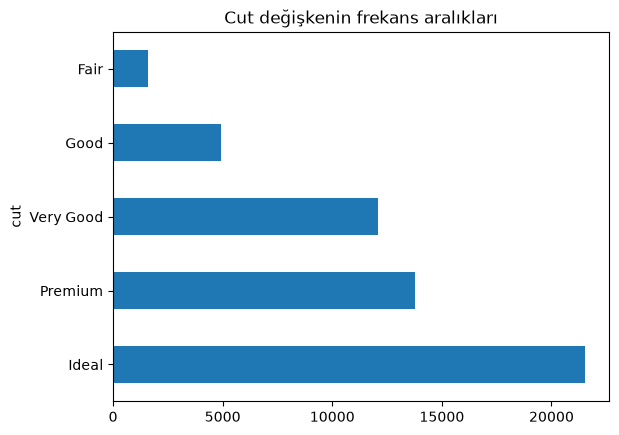

In [151]:
(df["cut"]
.value_counts()
.plot.barh()
.set_title("Cut değişkenin frekans aralıkları"));

<Axes: xlabel='cut', ylabel='count'>

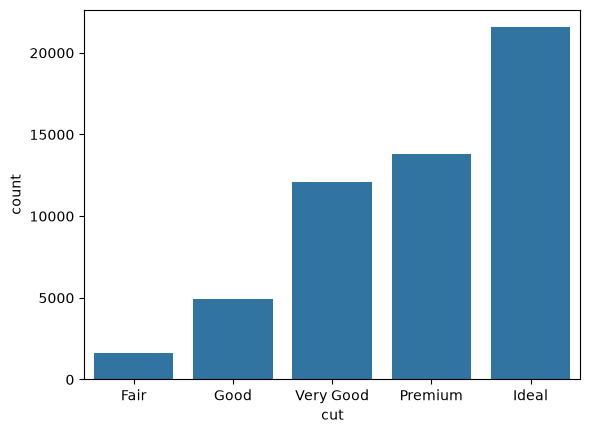

In [166]:
import seaborn as sns
sns.countplot(x="cut", data=df)

#### Çaprazlamalar


In [168]:
import seaborn as sns
from pandas.api.types import CategoricalDtype
diamonds = sns.load_dataset('diamonds')
df = diamonds.copy()
cut_kategoriler = ["Fair","Good","Very Good","Premium","Ideal"]
df.cut = df.cut.astype(CategoricalDtype(categories = cut_kategoriler, ordered = True))
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


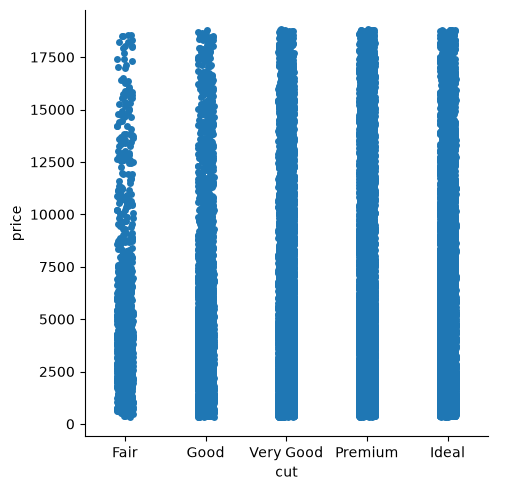

In [ ]:
sns.catplot(x="cut",y="price",data=df) #kind=strip default olarak
#grafikteki her bir nokta bir elması ifade eder

<Axes: xlabel='cut', ylabel='price'>

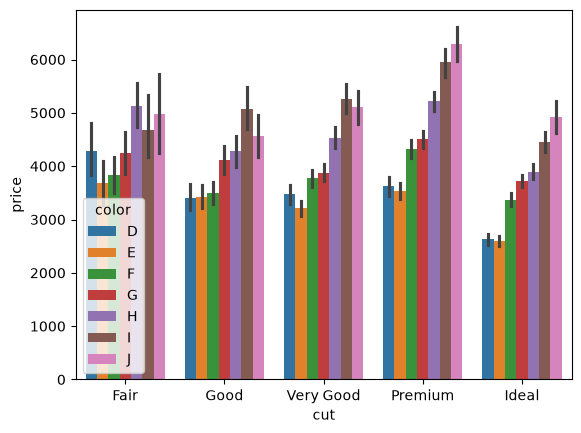

In [ ]:
#grafiğe boyut katma
#barplot default olarak ortalama değer gösterir
sns.barplot(x="cut", y="price", hue="color",data=df)

In [ ]:
#Yukarıdaki grafik ile aynı şeyi yapıyor aslında. Bu grafikteki ince çubuklar güven aralığını gösterir.
df.groupby(["cut","color"])["price"].mean()

cut        color
Fair       D        4291.061350
           E        3682.312500
           F        3827.003205
           G        4239.254777
           H        5135.683168
           I        4685.445714
           J        4975.655462
Good       D        3405.382175
           E        3423.644159
           F        3495.750275
           G        4123.482204
           H        4276.254986
           I        5078.532567
           J        4574.172638
Very Good  D        3470.467284
           E        3214.652083
           F        3778.820240
           G        3872.753806
           H        4535.390351
           I        5255.879568
           J        5103.513274
Premium    D        3631.292576
           E        3538.914420
           F        4324.890176
           G        4500.742134
           H        5216.706780
           I        5946.180672
           J        6294.591584
Ideal      D        2629.094566
           E        2597.550090
           F        337

#### Histogram

In [8]:
import seaborn as sns
from pandas.api.types import CategoricalDtype
diamonds = sns.load_dataset('diamonds')
df = diamonds.copy()
cut_kategoriler = ["Fair","Good","Very Good","Premium","Ideal"]
df.cut = df.cut.astype(CategoricalDtype(categories = cut_kategoriler, ordered = True))
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


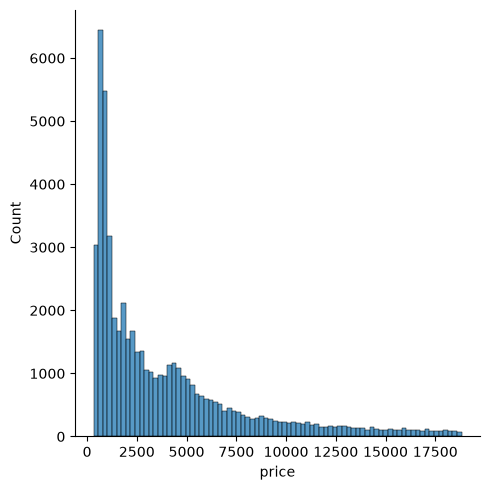

In [5]:
sns.displot(df.price, kde=False)

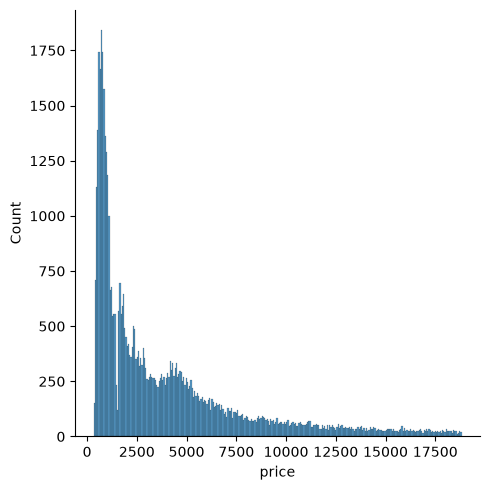

In [13]:
sns.displot(df.price, bins = 300, kde=False)
#grafik, veri setindeki fiyatların hangi aralıklarda ve ne sıklıkla bulunduğunu gösteriyor.

<Axes: xlabel='price', ylabel='Density'>

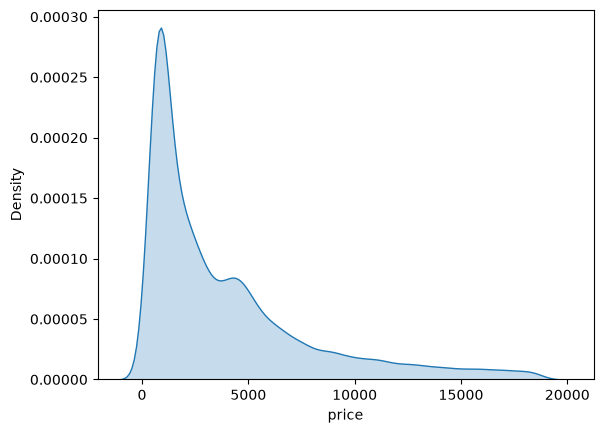

In [ ]:
#Dağılımın genel şeklini gösterir
sns.kdeplot(df.price, fill = True)

<Axes: xlabel='price', ylabel='Count'>

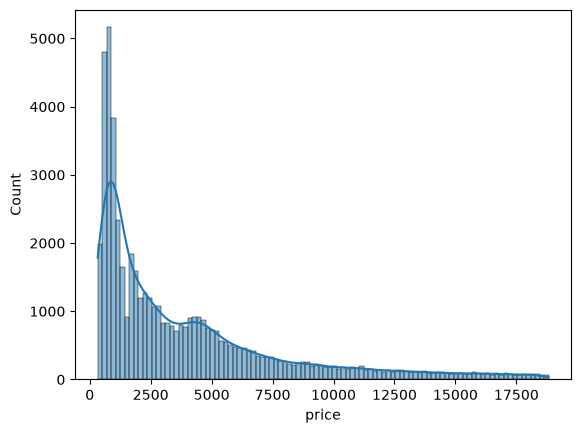

In [ ]:
#Histogram ve KDE'i beraber kullanmak istersek
sns.histplot(
    data=df,
    x="price",
    bins=100,
    kde=True
)

#### Çaprazlamalar

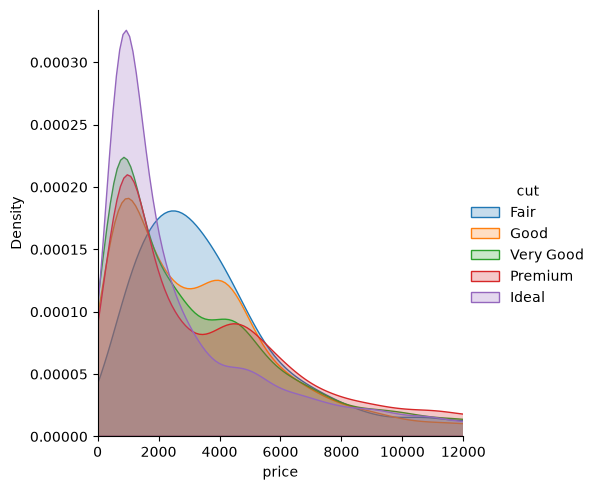

In [9]:
(sns
 .FacetGrid(df, hue="cut", height=5, xlim=(0,12000))
 .map(sns.kdeplot, "price", fill=True)
 .add_legend()
)
#Hangi kesim kalitesindeki elmaslar, hangi fiyat aralıklarında yoğunlaşıyor?

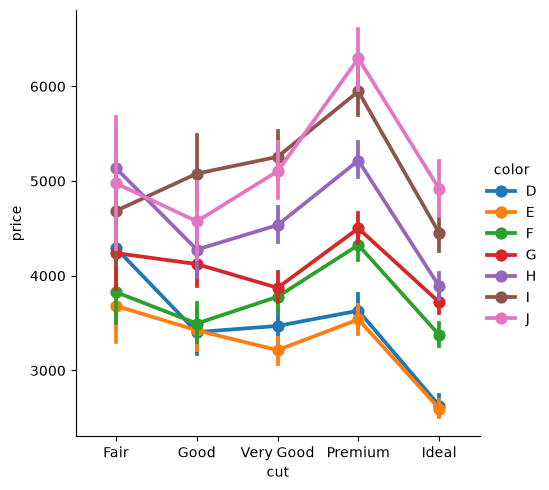

In [11]:
sns.catplot(x="cut", y="price", hue="color", kind="point", data=df)
#Her nokta, o cut ve color grubundaki elmasların ortalama fiyatını gösteriyor. Noktaların üstündeki ve altındaki çizgiler güven aralıklarıdır.

#### Veri Seti Hikayesi - 2

total_bill: yemeğin toplam fiyatı (bahşiş ve vergi dahil)

tip: bahşiş

sex: ücreti ödeyen kişinin cinsiyeti (0=male, 1=female)

smoker: grupta sigara içen var mı? (0=No, 1=Yes)

day: gün (3=Thur, 4=Fri, 5=Sat, 6=Sun)

time: ne zaman? (0=Day, 1=Night)

size: grupta kaç kişi var?

In [12]:
import seaborn as sns
tips = sns.load_dataset("tips")
df = tips.copy()
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
size,244.0,2.569672,0.951100,1.00,2.0000,2.000,3.0000,6.00


In [24]:
df["smoker"].value_counts()

smoker
No     151
Yes     93
Name: count, dtype: int64

In [25]:
df["sex"].value_counts()

sex
Male      157
Female     87
Name: count, dtype: int64

In [26]:
df["day"].value_counts()

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

In [27]:
df["time"].value_counts()

time
Dinner    176
Lunch      68
Name: count, dtype: int64

#### Boxplot

<Axes: xlabel='total_bill'>

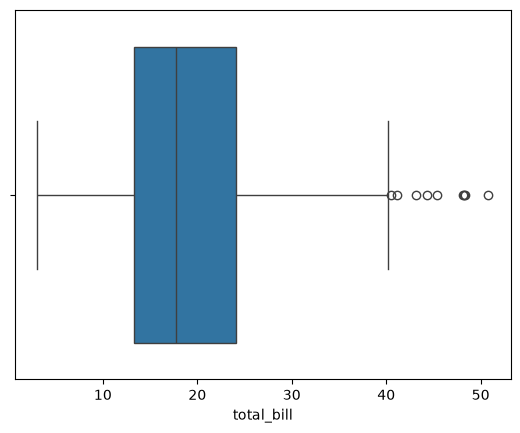

In [48]:
sns.boxplot(x=df["total_bill"], orient="h")
#soldaki dikey çizgi min, en sağdaki max değer
#sağdaki dikey çizginin dışındakiler outlier değerdir
#mavi kutucuğun solu %25. değer, ortadaki medyan, sağdaki %75'i değer

#### Çaprazlamalar

<Axes: xlabel='day', ylabel='total_bill'>

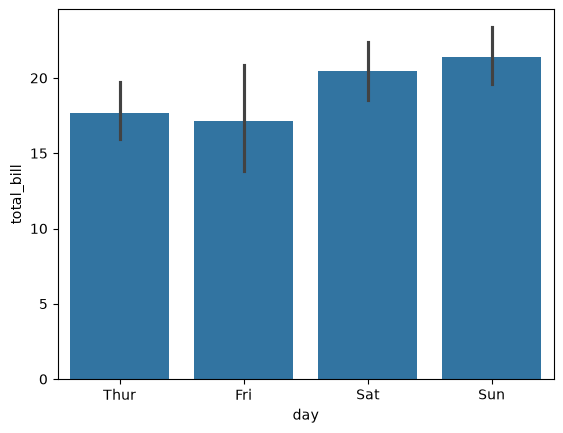

In [84]:
sns.barplot(x=df["day"], y=df["total_bill"], data=df)


In [13]:
print(df.groupby("day")["total_bill"].sum())
print(df.groupby("day")["total_bill"].mean())
print(df.groupby("day").size())

day
Thur    1096.33
Fri      325.88
Sat     1778.40
Sun     1627.16
Name: total_bill, dtype: float64
day
Thur    17.682742
Fri     17.151579
Sat     20.441379
Sun     21.410000
Name: total_bill, dtype: float64
day
Thur    62
Fri     19
Sat     87
Sun     76
dtype: int64


day         Thur        Fri        Sat        Sun
count  62.000000  19.000000  87.000000  76.000000
mean   17.682742  17.151579  20.441379  21.410000
std     7.886170   8.302660   9.480419   8.832122
min     7.510000   5.750000   3.070000   7.250000
25%    12.442500  12.095000  13.905000  14.987500
50%    16.200000  15.380000  18.240000  19.630000
75%    20.155000  21.750000  24.740000  25.597500
max    43.110000  40.170000  50.810000  48.170000


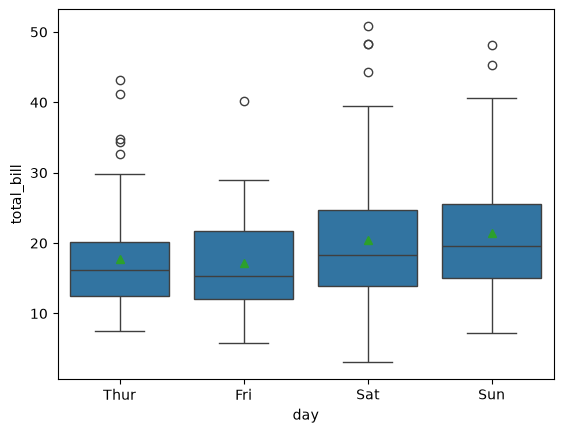

In [88]:
sns.boxplot(x=df["day"], y=df["total_bill"], data=df, showmeans=True)
print(df.groupby("day")["total_bill"].describe().T)
#hangi gün daha çok para harcanıyor

<Axes: xlabel='time', ylabel='total_bill'>

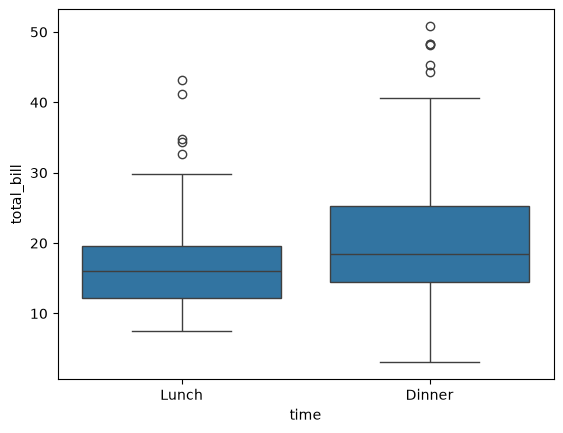

In [81]:
sns.boxplot(x=df["time"], y=df["total_bill"], data=df)
#sabah mı akşam mı daha çok para harcanıyor

<Axes: xlabel='size', ylabel='total_bill'>

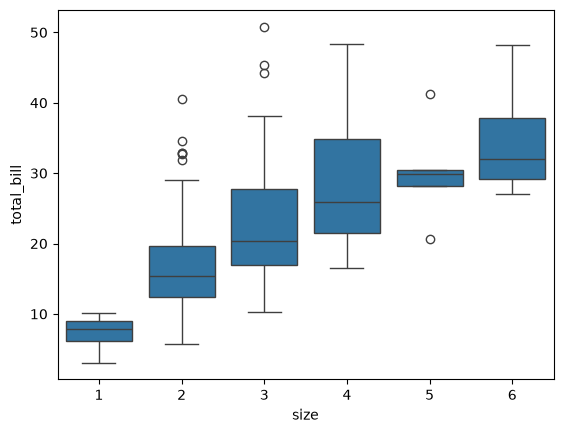

In [80]:
sns.boxplot(x=df["size"], y=df["total_bill"], data=df)
#kalabalık gruplar mı daha çok para harcıyor

<Axes: xlabel='day', ylabel='total_bill'>

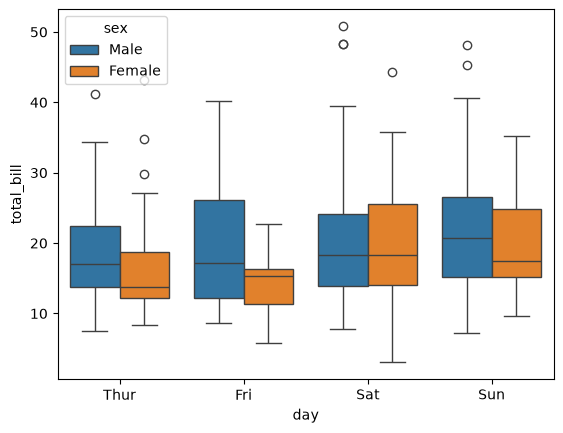

In [30]:
sns.boxplot(x=df["day"], y=df["total_bill"], hue="sex" ,data=df)


#### Violin Grafiği

In [26]:
import seaborn as sns
tips = sns.load_dataset("tips")
df = tips.copy()
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


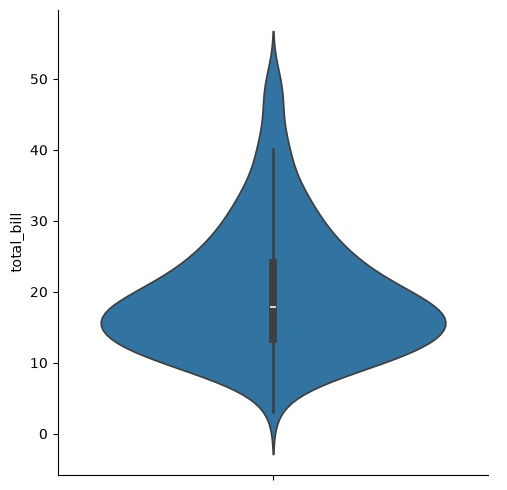

In [20]:
sns.catplot(y="total_bill", kind="violin", data=df)

#### Çaprazlamalar

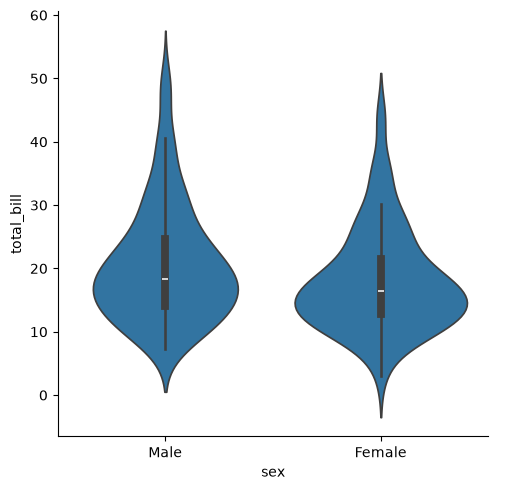

In [ ]:
#Violin genişliği(bu örnekte o hesap tutarı civarındaki veri yoğunluğunu), medyanı, Q1-Q3 arasını gösterir
sns.catplot(y="total_bill", x="sex", kind="violin", data=df)

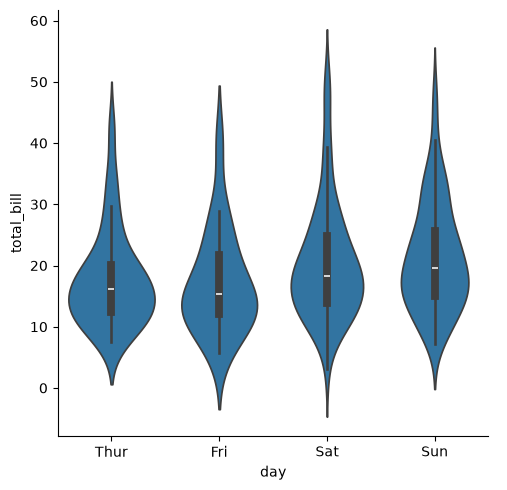

In [22]:
sns.catplot(y="total_bill", x="day", kind="violin", data=df)

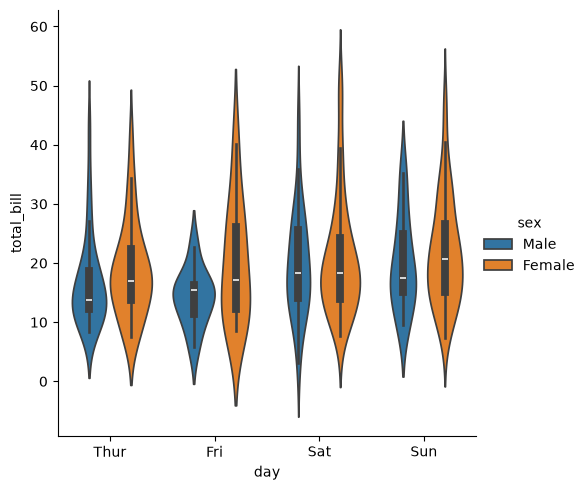

In [27]:
sns.catplot(y="total_bill", x="day", hue="sex", kind="violin", data=df)

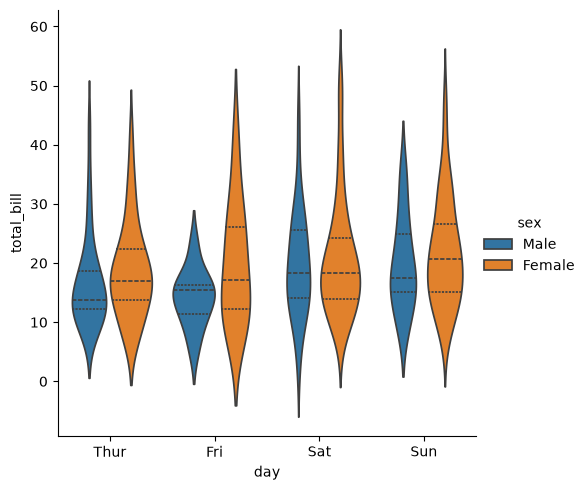

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

sns.catplot(
    data=df,
    x="day",
    y="total_bill",
    hue="sex",
    kind="violin",
    inner="quartile"
)

plt.show()

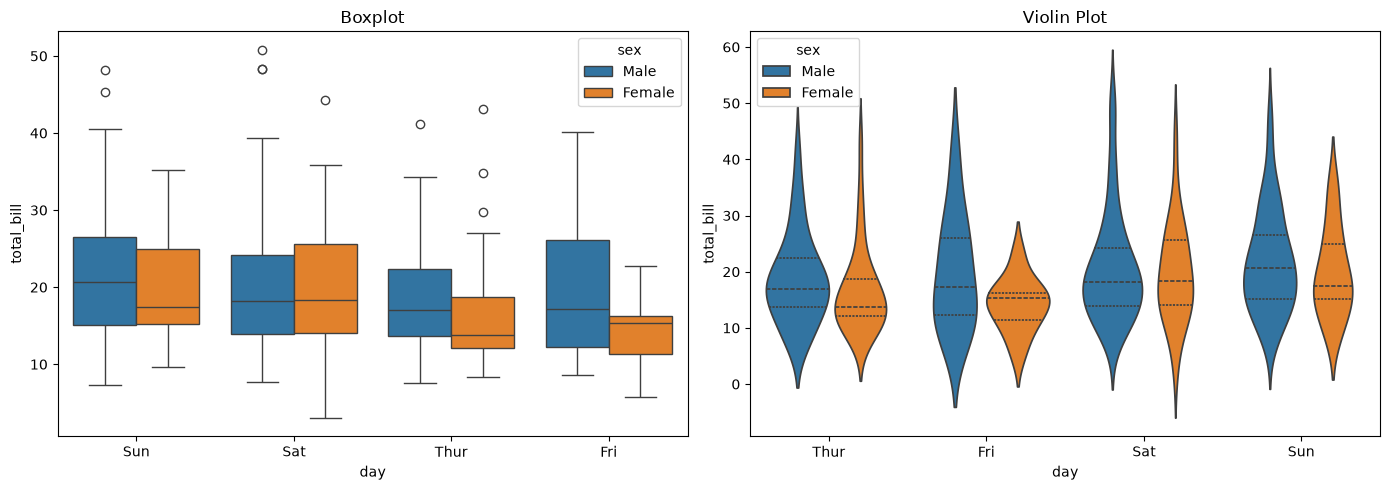

" \nfig: Bütün grafiklerin bulunduğu ana alan (Figure).\naxes: Her bir grafiğin çizildiği ayrı alanlar (Axes).\n\n1: Satır sayısı.\n2: Sütun sayısı.\nfigsize=(14, 5): Figure'ın genişliği 14, yüksekliği 5 inç.\n\nplt.tight_layout(): Bu komut grafikler arasındaki boşlukları otomatik olarak ayarlamaya çalışır.\n"

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df = sns.load_dataset("tips")

df_fixed = df.copy()
df_fixed["sex"] = df_fixed["sex"].astype(str)
df_fixed["day"] = df_fixed["day"].astype(str)

sns.boxplot(
    data=df_fixed,
    x="day",
    y="total_bill",
    hue="sex",
    hue_order=["Male", "Female"],
    ax=axes[0]
)

sns.violinplot(
    data=df_fixed,
    x="day",
    y="total_bill",
    hue="sex",
    order=["Thur", "Fri", "Sat", "Sun"],
    hue_order=["Male", "Female"],
    inner="quartile",
    ax=axes[1]
)

axes[0].set_title("Boxplot")
axes[1].set_title("Violin Plot")

plt.tight_layout()
plt.show()

''' 
fig: Bütün grafiklerin bulunduğu ana alan (Figure).
axes: Her bir grafiğin çizildiği ayrı alanlar (Axes).

1: Satır sayısı.
2: Sütun sayısı.
figsize=(14, 5): Figure'ın genişliği 14, yüksekliği 5 inç.

plt.tight_layout(): Bu komut grafikler arasındaki boşlukları otomatik olarak ayarlamaya çalışır.
'''

#### Korelasyon Grafiği